# Preprocessing e Domanda di Ricerca

Continua da dove finisce l'EDA in `SAD.ipynb`. Contiene il Task 1 (dipendenze tra feature), Task 2 (valori nulli e dipendenze), e il Task 3 (RQ sulla traiettoria A1C).

Il notebook funziona da solo: la cella dopo ricarica il dataset e ricrea le colonne derivate usate nell'EDA, quindi non serve eseguire prima SAD.ipynb.

## Setup

In [1]:
library(dplyr)
library(readr)
library(ggplot2)
library(tidyr)
library(stringr)
library(corrplot)
library(lsr) 

theme_set(theme_bw() +
          theme(plot.title = element_text(face = "bold", size = 18),
                plot.subtitle = element_text(size = 17)))
options(repr.plot.width = 18, repr.plot.height = 10)

Rscript.exe : Avvertimento: il pacchetto 'dplyr' è stato creato con R versione 4.6.1
In riga:3 car:1
+ & $Rscript "C:\Users\Cam\AppData\Local\Temp\claude\C--Users-Cam-OneDr ...
+ ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
    + CategoryInfo          : NotSpecified: (Avvertimento: i... versione 4.6.1:String) [], RemoteException
    + FullyQualifiedErrorId : NativeCommandError
 

Caricamento pacchetto: 'dplyr'

I seguenti oggetti sono mascherati da 'package:stats':

    filter, lag

I seguenti oggetti sono mascherati da 'package:base':

    intersect, setdiff, setequal, union

Avvertimento: il pacchetto 'readr' è stato creato con R versione 4.6.1
Avvertimento: il pacchetto 'ggplot2' è stato creato con R versione 4.6.1
Avvertimento: il pacchetto 'tidyr' è stato creato con R versione 4.6.1
Avvertimento: il pacchetto 'stringr' è stato creato con R versione 4.6.1
Avvertimento: il pacchetto 'corrplot' è stato creato con R versione 4.6.1
corrplot 0.95 loaded
Avvertim

In [2]:
df <- read_csv('diabetic_data.csv', na = c("?"), show_col_types = FALSE)

cat(sprintf("Dimensioni del dataset: %s righe x %s colonne\n",
            format(nrow(df), big.mark=","), ncol(df)))

Dimensioni del dataset: 101,766 righe x 50 colonne


Ricreiamo le colonne derivate già usate nell'EDA:
- `admission_type_desc`, `discharge_disposition_desc`, `admission_source_desc`: mappatura dei codici amministrativi
- `diag_1_category`: raggruppamento dei codici ICD 9 in 9 categorie

In [3]:
admission_type_map <- c(
  "1" = "Emergency", "2" = "Urgent", "3" = "Elective", "4" = "Newborn",
  "5" = "Not Available", "6" = "NULL", "7" = "Trauma Center", "8" = "Not Mapped"
)

discharge_disposition_map <- c(
  "1" = "Discharged to home", "2" = "Transferred - short term hospital", "3" = "Transferred - SNF",
  "4" = "Transferred - ICF", "5" = "Transferred - other inpatient care institution",
  "6" = "Home health service", "7" = "Left AMA", "8" = "Home under care of Home IV provider",
  "9" = "Admitted as inpatient to this hospital", "10" = "Neonate to another hospital",
  "11" = "Expired", "12" = "Still patient / expected to return", "13" = "Hospice / home",
  "14" = "Hospice / medical facility", "15" = "Transferred - within institution to swing bed",
  "16" = "Transferred/referred to outpatient services (other inst.)",
  "17" = "Transferred/referred to outpatient services (this inst.)", "18" = "NULL",
  "19" = "Expired at home (Medicaid hospice)", "20" = "Expired in medical facility (Medicaid hospice)",
  "21" = "Expired, place unknown (Medicaid hospice)", "22" = "Transferred - rehab facility",
  "23" = "Transferred - long term care hospital", "24" = "Transferred - nursing facility (Medicaid only)",
  "25" = "Not Mapped", "26" = "Unknown/Invalid", "27" = "Transferred - federal health care facility",
  "28" = "Transferred - psychiatric hospital", "29" = "Transferred - Critical Access Hospital",
  "30" = "Transferred - other type of health care institution"
)

admission_source_map <- c(
  "1" = "Physician Referral", "2" = "Clinic Referral", "3" = "HMO Referral", "4" = "Transfer from a hospital",
  "5" = "Transfer from SNF", "6" = "Transfer from another health care facility", "7" = "Emergency Room",
  "8" = "Court/Law Enforcement", "9" = "Not Available", "10" = "Transfer from critical access hospital",
  "11" = "Normal Delivery", "12" = "Premature Delivery", "13" = "Sick Baby", "14" = "Extramural Birth",
  "15" = "Not Available", "17" = "NULL", "18" = "Transfer from another Home Health Agency",
  "19" = "Readmission to Same Home Health Agency", "20" = "Not Mapped", "21" = "Unknown/Invalid",
  "22" = "Transfer from hospital inpt (separate claim)", "23" = "Born inside this hospital",
  "24" = "Born outside this hospital", "25" = "Transfer from Ambulatory Surgery Center",
  "26" = "Transfer from Hospice"
)

df <- df %>%
  mutate(
    admission_type_desc = unname(admission_type_map[as.character(admission_type_id)]),
    discharge_disposition_desc = unname(discharge_disposition_map[as.character(discharge_disposition_id)]),
    admission_source_desc = unname(admission_source_map[as.character(admission_source_id)])
  )

df <- df %>%
  mutate(
    val = suppressWarnings(as.numeric(diag_1)),
    diag_1_category = case_when(
      is.na(diag_1) ~ "Missing",
      str_detect(diag_1, "^[VE]") ~ "Other",
      str_detect(diag_1, "^250") ~ "Diabetes",
      (val >= 390 & val <= 459) | val == 785 ~ "Circulatory",
      (val >= 460 & val <= 519) | val == 786 ~ "Respiratory",
      (val >= 520 & val <= 579) | val == 787 ~ "Digestive",
      (val >= 580 & val <= 629) | val == 788 ~ "Genitourinary",
      val >= 800 & val <= 999 ~ "Injury",
      val >= 710 & val <= 739 ~ "Musculoskeletal",
      val >= 140 & val <= 239 ~ "Neoplasms",
      TRUE ~ "Other"
    )
  ) %>%
  select(-val)

---

## Task 1: dipendenze tra feature

Controlliamo quanto le feature sono legate tra loro, prima del clustering. Il test cambia in base al tipo di variabile:

- Numeriche vs numeriche: correlazione di Spearman
- Categoriche vs categoriche: Chi quadro + V di Cramér
- Categoriche vs target (`readmitted`): stesso approccio
- Numeriche vs categoriche: Kruskal Wallis + epsilon quadro

Con più di 100.000 osservazioni il p value è quasi sempre bassissimo anche per legami irrilevanti, quindi guardiamo l'effect size (V di Cramér, ε²) invece del solo p value.

[1] "--- Matrice di Correlazione di Spearman (Variabili Numeriche) ---"
                   time_in_hospital num_lab_procedures num_procedures
time_in_hospital               1.00               0.34           0.19
num_lab_procedures             0.34               1.00           0.02
num_procedures                 0.19               0.02           1.00
num_medications                0.47               0.25           0.35
number_outpatient             -0.01              -0.02          -0.02
number_emergency               0.00               0.01          -0.05
number_inpatient               0.09               0.04          -0.06
                   num_medications number_outpatient number_emergency
time_in_hospital              0.47             -0.01             0.00
num_lab_procedures            0.25             -0.02             0.01
num_procedures                0.35             -0.02            -0.05
num_medications               1.00              0.07             0.04
number_outpatient 

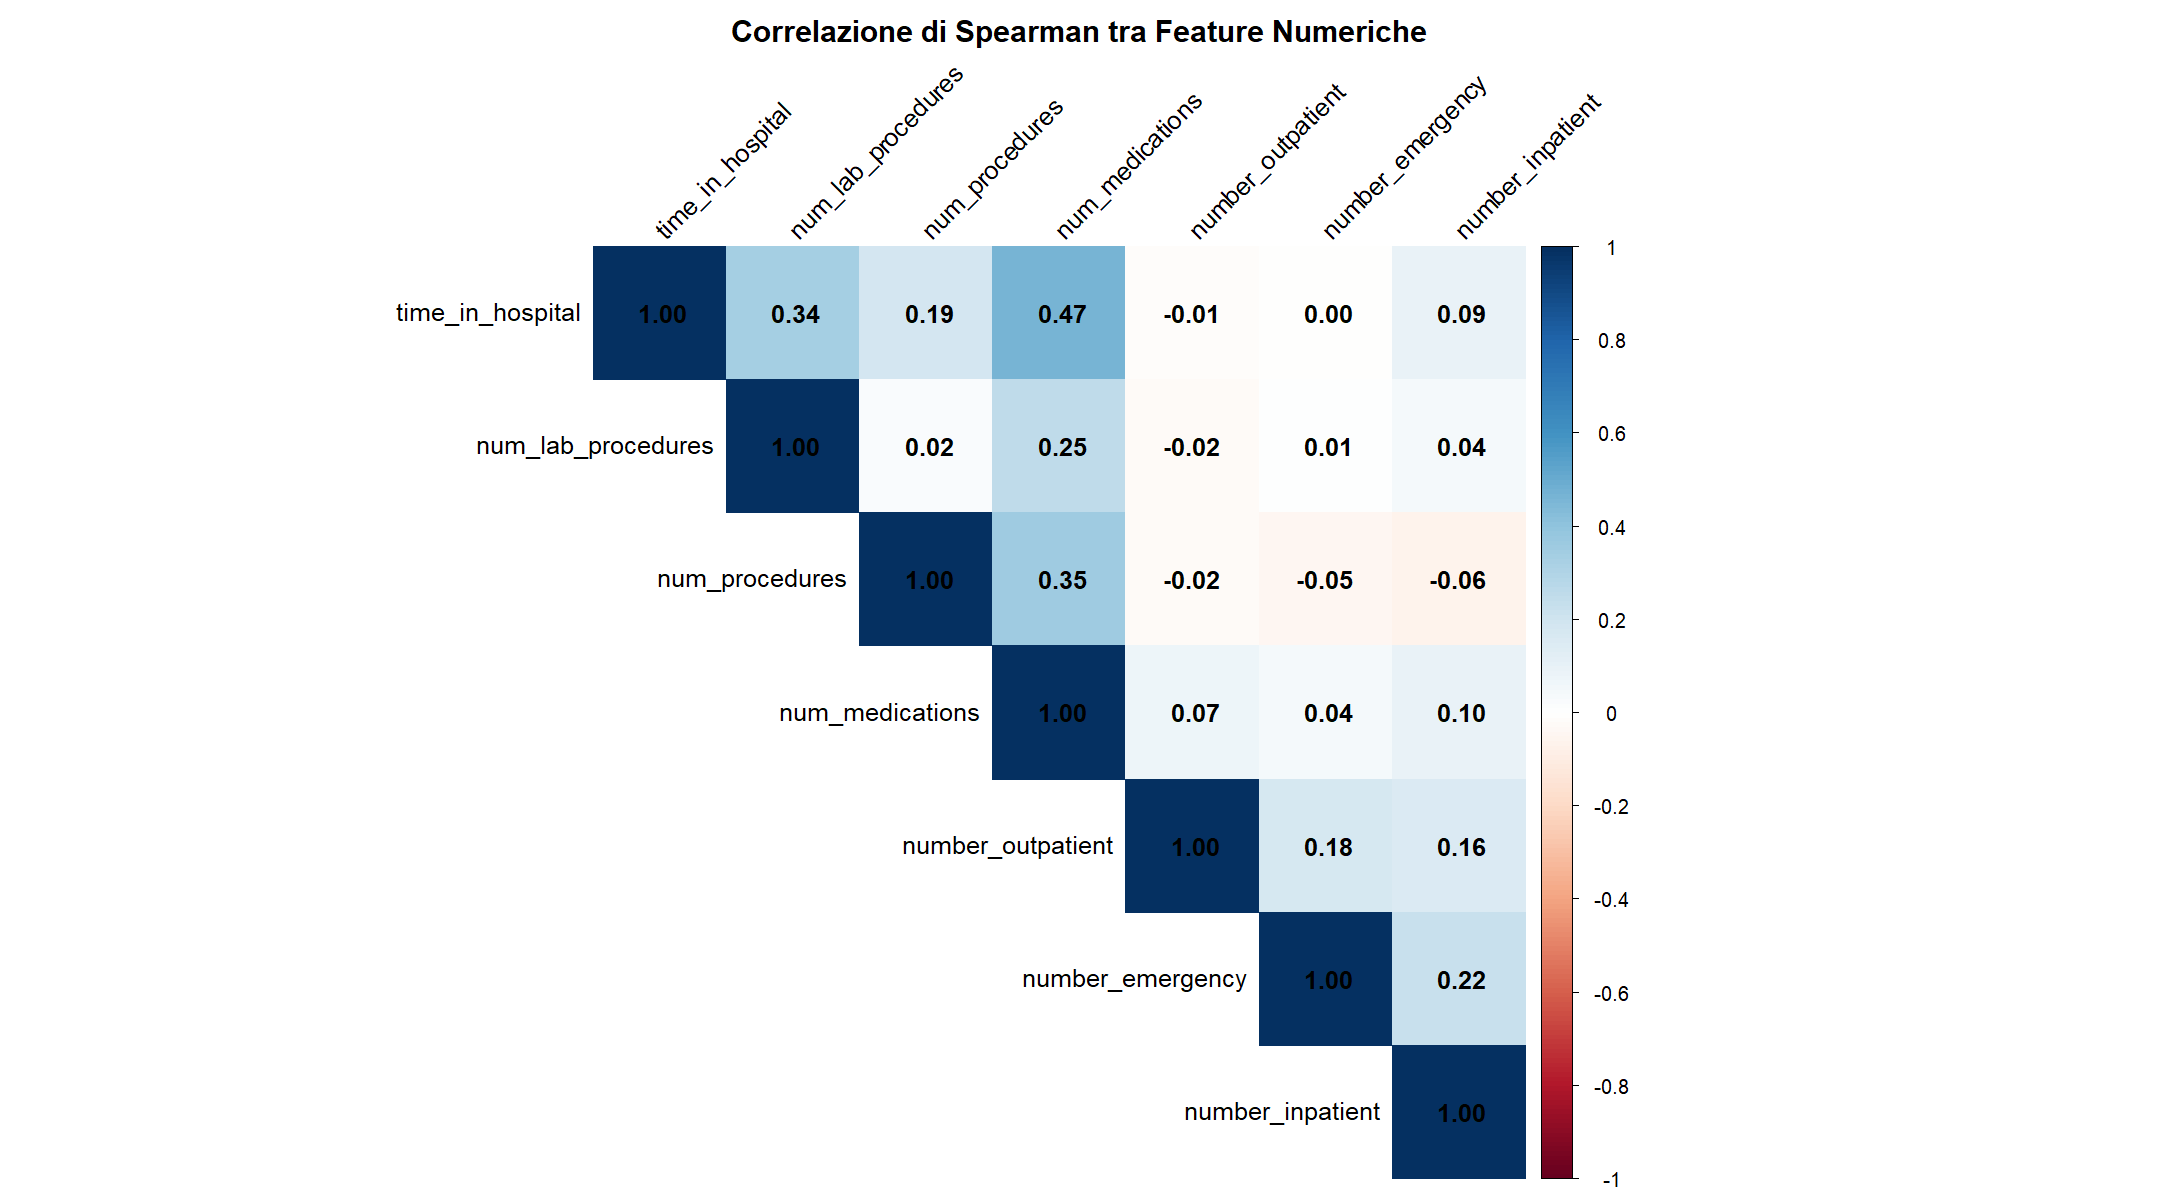

In [4]:
num_vars <- df %>%
  select(time_in_hospital, num_lab_procedures, num_procedures,
         num_medications, number_outpatient, number_emergency, number_inpatient)

cor_matrix_spearman <- cor(num_vars, method = "spearman", use = "complete.obs")

print("--- Matrice di Correlazione di Spearman (Variabili Numeriche) ---")
print(round(cor_matrix_spearman, 2))

corrplot(cor_matrix_spearman, method = "color", type = "upper",
         tl.col = "black", tl.srt = 45, addCoef.col = "black",
         title = "Correlazione di Spearman tra Feature Numeriche", mar = c(0, 0, 2, 0))

### Interpretazione: dipendenza tra variabili numeriche

Collinearità bassa in generale. La correlazione più alta è tra `time_in_hospital` e `num_medications` (0.47), poi `num_lab_procedures` (0.34): ricoveri più lunghi comportano più farmaci e più esami. Le variabili sullo storico sanitario (`number_emergency`, `number_outpatient`) non correlano quasi per niente con il ricovero attuale. Nessuna coppia supera 0.70, quindi tutte le numeriche si possono usare insieme senza problemi di ridondanza.

### Dipendenza tra variabili categoriche

Qui guardiamo la dipendenza tra le feature categoriche stesse, non con il target, per capire se alcune portano informazione ridondante (per esempio `change`, `diabetesMed`, `insulin`).

Per ogni coppia calcoliamo Chi quadro e V di Cramér (0 è indipendenza, 1 è dipendenza perfetta). Come riferimento: sotto 0.1 trascurabile, tra 0.1 e 0.3 debole o moderata, sopra 0.3 forte.

Avvertimento in stats::chisq.test(...):
  L'approssimazione al Chi-quadrato potrebbe essere inesatta
Avvertimento in stats::chisq.test(...):
  L'approssimazione al Chi-quadrato potrebbe essere inesatta
Avvertimento in stats::chisq.test(...):
  L'approssimazione al Chi-quadrato potrebbe essere inesatta
Avvertimento in stats::chisq.test(...):
  L'approssimazione al Chi-quadrato potrebbe essere inesatta
Avvertimento in stats::chisq.test(...):
  L'approssimazione al Chi-quadrato potrebbe essere inesatta
Avvertimento in stats::chisq.test(...):
  L'approssimazione al Chi-quadrato potrebbe essere inesatta
Avvertimento in stats::chisq.test(...):
  L'approssimazione al Chi-quadrato potrebbe essere inesatta
Avvertimento in stats::chisq.test(...):
  L'approssimazione al Chi-quadrato potrebbe essere inesatta
Avvertimento in stats::chisq.test(...):
  L'approssimazione al Chi-quadrato potrebbe essere inesatta
Avvertimento in stats::chisq.test(...):
  L'approssimazione al Chi-quadrato potrebbe essere

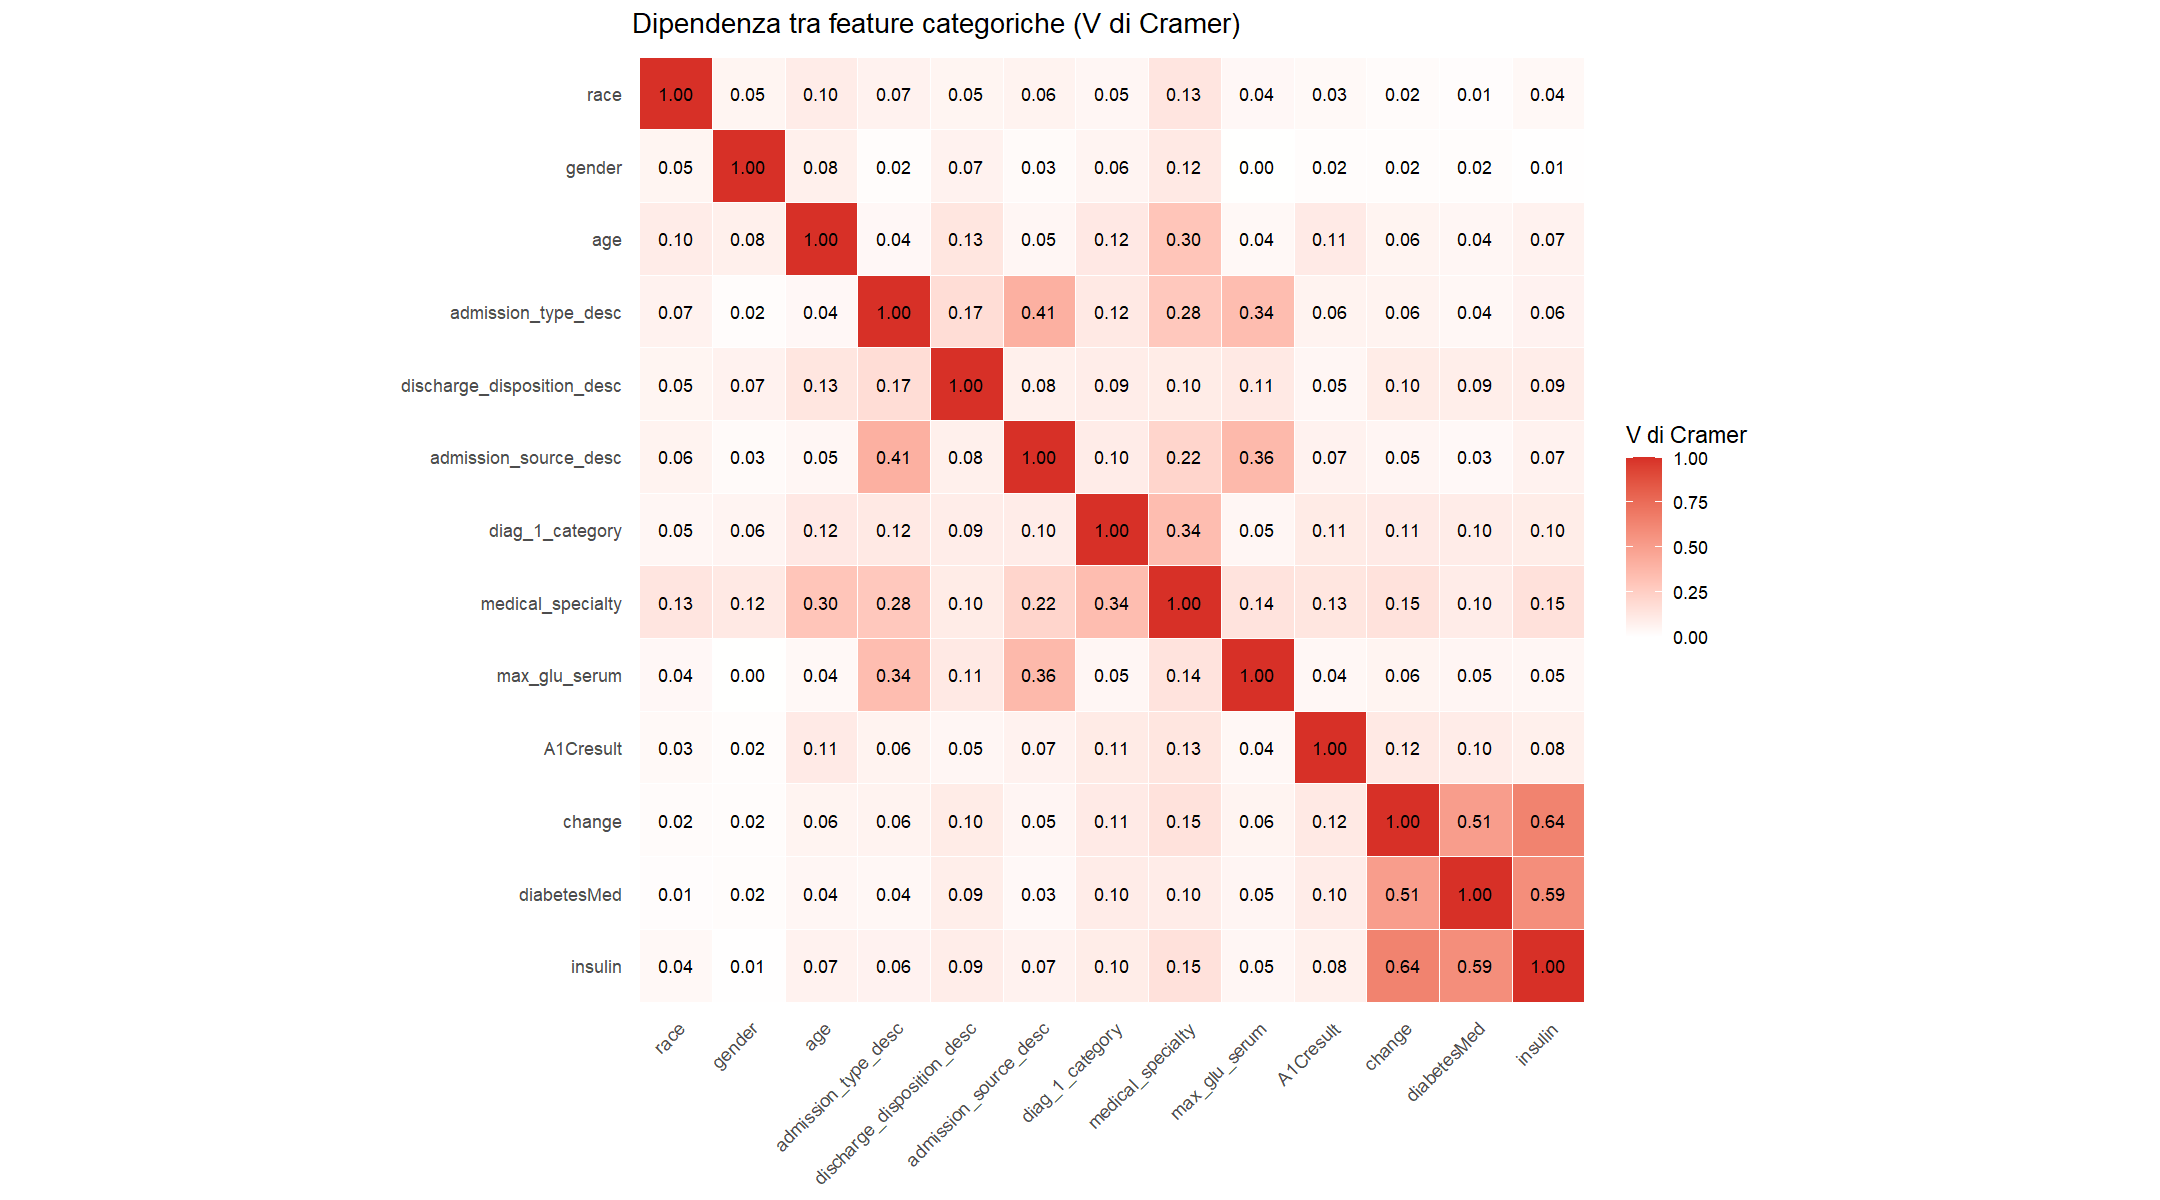

In [5]:
cat_vars_all <- c("race", "gender", "age", "admission_type_desc", "discharge_disposition_desc",
                   "admission_source_desc", "diag_1_category", "medical_specialty",
                   "max_glu_serum", "A1Cresult", "change", "diabetesMed", "insulin")

pairwise_results <- data.frame(Var1 = character(), Var2 = character(),
                                Cramer_V = numeric(), Chi2_p_value = numeric(),
                                stringsAsFactors = FALSE)

for (i in 1:(length(cat_vars_all) - 1)) {
  for (j in (i + 1):length(cat_vars_all)) {
    v1 <- cat_vars_all[i]
    v2 <- cat_vars_all[j]
    tbl <- table(df[[v1]], df[[v2]])
    tbl <- tbl[rowSums(tbl) > 0, colSums(tbl) > 0, drop = FALSE]
    chi2 <- suppressWarnings(chisq.test(tbl))
    cv <- cramersV(tbl)
    pairwise_results <- pairwise_results %>%
      add_row(Var1 = v1, Var2 = v2, Cramer_V = cv, Chi2_p_value = chi2$p.value)
  }
}

print("--- Top 10 coppie di feature categoriche piu' associate (V di Cramer) ---")
print(pairwise_results %>% arrange(desc(Cramer_V)) %>% head(10))


pairwise_matrix <- bind_rows(
  pairwise_results,
  pairwise_results %>% rename(Var1 = Var2, Var2 = Var1),
  data.frame(Var1 = cat_vars_all, Var2 = cat_vars_all, Cramer_V = 1, Chi2_p_value = 0)
)

p_cramer <- ggplot(pairwise_matrix, aes(x = factor(Var1, levels = cat_vars_all),
                                          y = factor(Var2, levels = rev(cat_vars_all)),
                                          fill = Cramer_V)) +
  geom_tile(color = "white") +
  geom_text(aes(label = sprintf("%.2f", Cramer_V)), size = 3) +
  scale_fill_gradient(low = "white", high = "#d73027", limit = c(0, 1), name = "V di Cramer") +
  coord_fixed() +
  labs(title = "Dipendenza tra feature categoriche (V di Cramer)", x = NULL, y = NULL) +
  theme_minimal() +
  theme(axis.text.x = element_text(angle = 45, hjust = 1),
        panel.grid.major = element_blank())

p_cramer

### Interpretazione: dipendenza tra variabili categoriche

`change`, `diabetesMed` e `insulin` sono molto legate tra loro (V tra 0.51 e 0.64, i valori più alti del dataset). Ha senso: `insulin` è il farmaco più usato e modificato, quindi influenza sia `change` che `diabetesMed`. Conviene non usarle tutte e tre come feature indipendenti nel clustering.

`admission_type_desc` e `admission_source_desc` hanno V ≈ 0.41, `diag_1_category` e `medical_specialty` V ≈ 0.34: entrambe relazioni plausibili.

C'è anche un'anomalia di data quality: `max_glu_serum` è legato a `admission_source_desc` e `admission_type_desc` (V ≈ 0.34 e 0.36), ma il motivo è un codice `"NULL"` non mappato nei dati amministrativi, non un segnale clinico. Probabilmente diversi ospedali del dataset codificano i dati in modo diverso.

Tutte le altre coppie restano sotto V = 0.22, dipendenza debole o trascurabile.

### Dipendenza tra variabili categoriche e target

Stesso approccio, Chi quadro e V di Cramér, applicato al legame di ogni categorica con `readmitted`, per vedere quali feature portano più segnale predittivo.

In [6]:

cat_vars <- c("race", "gender", "age", "medical_specialty", "max_glu_serum", "A1Cresult", "change", "diabetesMed")
dependency_results <- data.frame(Variable = character(), Chi2_p_value = numeric(), Cramer_V = numeric(), stringsAsFactors = FALSE)

for (var in cat_vars) {
  contingency_table <- table(df[[var]], df$readmitted)
  chi2_test <- suppressWarnings(chisq.test(contingency_table))
  cramer_v <- cramersV(contingency_table)

  dependency_results <- dependency_results %>%
    add_row(Variable = var, Chi2_p_value = chi2_test$p.value, Cramer_V = cramer_v)
}

print("--- Dipendenza tra Feature Categoriche e Target (Readmitted) ---")
print(dependency_results %>% arrange(desc(Cramer_V)))

Avvertimento in stats::chisq.test(...):
  L'approssimazione al Chi-quadrato potrebbe essere inesatta
Avvertimento in stats::chisq.test(...):
  L'approssimazione al Chi-quadrato potrebbe essere inesatta
[1] "--- Dipendenza tra Feature Categoriche e Target (Readmitted) ---"
           Variable  Chi2_p_value   Cramer_V
1 medical_specialty 1.840428e-170 0.10844493
2       diabetesMed  1.175514e-84 0.06162820
3            change  1.362061e-47 0.04605211
4               age  9.348415e-56 0.03922608
5              race  5.957899e-17 0.02177958
6         A1Cresult  3.855751e-13 0.01856171
7     max_glu_serum  1.933304e-09 0.01597202
8            gender  1.447272e-07 0.01356670


### Interpretazione: dipendenza con il target

| Variabile | V di Cramér |
|---|---|
| `medical_specialty` | 0.108 |
| `diabetesMed` | 0.062 |
| `change` | 0.046 |
| `age` | 0.039 |
| `race` | 0.022 |
| `A1Cresult` | 0.019 |
| `max_glu_serum` | 0.016 |
| `gender` | 0.014 |

Il p value è quasi sempre sotto 0.001, ma i V di Cramér restano tutti bassi, anche `medical_specialty` che è il più alto. Nessuna variabile da sola spiega bene la riammissione, come già visto per le numeriche. Serve un approccio multivariato come il clustering.

### Dipendenza tra variabili numeriche e categoriche

Ultimo controllo: le feature numeriche variano in modo sistematico al variare di alcune categoriche? Usiamo Kruskal Wallis con epsilon quadro come effect size, stessa scala di R² (tra 0 e 1), interpretabile come quota di varianza spiegata dai gruppi.

In [7]:

compute_epsilon2 <- function(num_var, cat_var, data) {
  d <- data %>% filter(!is.na(.data[[num_var]]), !is.na(.data[[cat_var]]))
  kw <- kruskal.test(d[[num_var]] ~ as.factor(d[[cat_var]]))
  n <- nrow(d)
  k <- n_distinct(d[[cat_var]])
  eps2 <- (unname(kw$statistic) - k + 1) / (n - k)
  data.frame(Numerica = num_var, Categorica = cat_var, H = unname(kw$statistic),
             p_value = kw$p.value, epsilon2 = eps2, n = n, k = k)
}

kw_results <- bind_rows(
  compute_epsilon2("time_in_hospital", "diag_1_category", df),
  compute_epsilon2("num_medications", "medical_specialty", df)
)

print("--- Dipendenza tra Feature Numeriche e Categoriche (Kruskal-Wallis) ---")
print(kw_results)

[1] "--- Dipendenza tra Feature Numeriche e Categoriche (Kruskal-Wallis) ---"
          Numerica        Categorica         H       p_value    epsilon2      n
1 time_in_hospital   diag_1_category  847.2322 1.439515e-176 0.008237669 101766
2  num_medications medical_specialty 4183.2448  0.000000e+00 0.079471347  51817
   k
1 10
2 72


### Interpretazione: dipendenza numeriche/categoriche

| Numerica | Categorica | H | p value | ε² |
|---|---|---|---|---|
| `time_in_hospital` | `diag_1_category` | 847.2 | < 0.001 | 0.008 |
| `num_medications` | `medical_specialty` | 4183.2 | < 0.001 | 0.080 |

Entrambi i test sono significativi ma gli effect size sono piccoli. La categoria diagnostica spiega meno dell'1% della varianza del ricovero, la specialità medica circa l'8% del numero di farmaci, il legame più forte di questa sezione ma comunque debole.

### Conclusione Task 1

L'unico gruppo di feature davvero ridondante è quello della terapia insulinica (`change`, `diabetesMed`, `insulin`), più l'anomalia di data quality su `max_glu_serum`. Il resto delle variabili è abbastanza indipendente. Buon punto di partenza sia per il clustering sia per il Task 2 che segue.

---

## Task 2: valori nulli e imputazione

Per ogni colonna con valori mancanti, la scelta dipende da quanti sono e da cosa significa il dato mancante: errore di registrazione o informazione reale, come già fatto nell'EDA per il valore `"None"` in `A1Cresult` e `max_glu_serum`.

In [8]:

cols_da_gestire <- c("weight", "payer_code", "medical_specialty", "race", "diag_1", "diag_2", "diag_3")
missing_summary <- data.frame(
  colonna = cols_da_gestire,
  n_mancanti = sapply(cols_da_gestire, function(c) sum(is.na(df[[c]]))),
  pct_mancante = sapply(cols_da_gestire, function(c) round(100 * mean(is.na(df[[c]])), 2))
)
print(missing_summary %>% arrange(desc(pct_mancante)))

                            colonna n_mancanti pct_mancante
weight                       weight      98569        96.86
medical_specialty medical_specialty      49949        49.08
payer_code               payer_code      40256        39.56
race                           race       2273         2.23
diag_3                       diag_3       1423         1.40
diag_2                       diag_2        358         0.35
diag_1                       diag_1         21         0.02


### Decisioni

| Colonna | % mancante | Decisione | Perché |
|---|---|---|---|
| `weight` | 96.9% | Elimina la colonna | Quasi tutta mancante, nessuna informazione utile |
| `payer_code` | 39.6% | Categoria "Non specificato" | Missingness alta ma non totale, meglio non perdere il 60% restante |
| `medical_specialty` | 49.1% | Categoria "Non specificato" | È la feature più legata al target (Task 1), non va eliminata |
| `race` | 2.2% | Categoria "Unknown" | Pochi casi, ma imputare con la moda introdurrebbe un bias |
| `diag_1` | 0.02% | Elimina le righe | Diagnosi primaria non imputabile, solo 21 righe |
| `diag_2`, `diag_3` | 0.35% / 1.40% | Categoria "Non presente" | Probabile assenza reale di una seconda diagnosi, non errore |

`examide` e `citoglipton` hanno varianza nulla ma non sono un problema di valori mancanti, restano fuori da questo task.

In [9]:
df <- df %>% select(-weight)
df <- df %>%
  mutate(
    payer_code = replace_na(payer_code, "Non specificato"),
    medical_specialty = replace_na(medical_specialty, "Non specificato"),
    race = replace_na(race, "Unknown")
  )
n_before <- nrow(df)
df <- df %>% filter(!is.na(diag_1))
cat(sprintf("Righe eliminate per diag_1 mancante: %d\n", n_before - nrow(df)))

df <- df %>%
  mutate(
    diag_2 = replace_na(diag_2, "Non presente"),
    diag_3 = replace_na(diag_3, "Non presente")
  )

cat(sprintf("\nDimensioni del dataset dopo il Task 2: %s righe x %s colonne\n",
            format(nrow(df), big.mark=","), ncol(df)))

cols_verificate <- c("payer_code", "medical_specialty", "race", "diag_1", "diag_2", "diag_3")
cat("Valori mancanti residui:", sum(sapply(cols_verificate, function(c) sum(is.na(df[[c]])))), "\n")

Righe eliminate per diag_1 mancante: 21

Dimensioni del dataset dopo il Task 2: 101,745 righe x 53 colonne
Valori mancanti residui: 0 


### Interpretazione: Task 2

Il dataset passa da 101.766 a 101.745 righe (21 eliminate per `diag_1`) e da 50 a 53 colonne (`weight` tolta, ma il conteggio sale per le colonne derivate già create prima nel notebook). Zero valori mancanti residui nelle colonne gestite.

Il Task 3 non cambia in modo rilevante dopo questa pulizia: McNemar resta identico (χ² = 3.01, p = 0.083), la matrice di transizione tra visite consecutive varia solo di 12 transizioni su oltre 30.000.

### Analisi delle traiettorie cliniche (A1Cresult)

`A1Cresult` nel dataset non è un valore continuo ma una categoria (`None`, `Norm`, `>7`, `>8`), quindi la traiettoria clinica è mappata usando la soglia disponibile più vicina, >8% come scompenso grave.

I pazienti sono divisi tra chi ha un livello sotto controllo o moderato (`Norm` e `>7`, unite) e chi è in Scompenso Grave (`>8%`). Ordinando gli encounter per ogni paziente, la matrice di transizione mostra quanti pazienti entrano in scompenso grave e ne escono stabilizzati all'ultima visita osservata, e viceversa. Questa soglia è un'approssimazione rispetto al valore continuo di 9% richiesto, ancorata alla struttura categoriale reale dei dati.

In [10]:

library(tidyverse)

df_trajectory <- df %>%
  mutate(encounter_order = row_number()) %>% 
  group_by(patient_nbr) %>%
  arrange(encounter_order, .by_group = TRUE) %>%
  mutate(visit_number = row_number(),
         total_visits = n()) %>%
  mutate(clinical_status = case_when(
    A1Cresult == ">8"         ~ "Scompenso Grave (>8%)",
    A1Cresult %in% c("Norm", ">7") ~ "Controllo/Stabile (<=8%)",
    A1Cresult == "None"       ~ "Non Misurata",
    TRUE                      ~ "Non Rilevato"
  )) %>%
  ungroup()

df_multi_visit <- df_trajectory %>%
  filter(total_visits > 1) %>%
  group_by(patient_nbr) %>%
  summarise(
    first_status = first(clinical_status),
    last_status = last(clinical_status),
    total_visits = first(total_visits),
    has_changed = first_status != last_status
  ) %>%
  ungroup()

transition_matrix <- table(df_multi_visit$first_status, df_multi_visit$last_status)

print("--- MATRICE DI TRANSIZIONE CLINICA REALE (Prima vs Ultima Visita) ---")
print(transition_matrix)

Avvertimento: il pacchetto 'tidyverse' è stato creato con R versione 4.6.1
Avvertimento: il pacchetto 'forcats' è stato creato con R versione 4.6.1
Avvertimento: il pacchetto 'lubridate' è stato creato con R versione 4.6.1
── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ forcats   1.0.1     ✔ purrr     1.2.2
✔ lubridate 1.9.5     ✔ tibble    3.3.1
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
[1] "--- MATRICE DI TRANSIZIONE CLINICA REALE (Prima vs Ultima Visita) ---"
                          
                           Controllo/Stabile (<=8%) Non Misurata
  Controllo/Stabile (<=8%)                      220         1126
  Non Misurata                                  943        12317
  Scompenso Grave (>8%)                          77       

## Task 3.3: test di McNemar sulla persistenza dello stato

"Non Misurata" nella matrice sopra non è un vero stato clinico, è solo l'assenza dell'esame. Per il test usiamo solo i pazienti con stato noto sia alla prima che all'ultima visita, e applichiamo McNemar invece del Chi quadro, perché i dati sono appaiati sullo stesso paziente.

H0: le transizioni Controllo verso Scompenso e Scompenso verso Controllo sono ugualmente probabili.
H1: una direzione prevale sull'altra.

In [11]:
df_known_both <- df_multi_visit %>%
  filter(first_status %in% c("Controllo/Stabile (<=8%)", "Scompenso Grave (>8%)"),
         last_status %in% c("Controllo/Stabile (<=8%)", "Scompenso Grave (>8%)")) %>%
  mutate(
    first_status = droplevels(factor(first_status)),
    last_status = droplevels(factor(last_status))
  )

cat(sprintf("Pazienti con stato clinico noto a entrambe le visite: %d\n", nrow(df_known_both)))

tbl_2x2 <- table(df_known_both$first_status, df_known_both$last_status)
print("--- Tabella 2x2 (solo stati noti) ---")
print(tbl_2x2)

mcnemar_result <- mcnemar.test(tbl_2x2, correct = TRUE)
print("--- Test di McNemar (con correzione di continuita') ---")
print(mcnemar_result)

n_peggiorati <- tbl_2x2["Controllo/Stabile (<=8%)", "Scompenso Grave (>8%)"]
n_migliorati <- tbl_2x2["Scompenso Grave (>8%)", "Controllo/Stabile (<=8%)"]
cat(sprintf("\nPeggiorati (Controllo -> Scompenso): %d\n", n_peggiorati))
cat(sprintf("Migliorati (Scompenso -> Controllo): %d\n", n_migliorati))

Pazienti con stato clinico noto a entrambe le visite: 649
[1] "--- Tabella 2x2 (solo stati noti) ---"
                          
                           Controllo/Stabile (<=8%) Scompenso Grave (>8%)
  Controllo/Stabile (<=8%)                      220                    56
  Scompenso Grave (>8%)                          77                   296
[1] "--- Test di McNemar (con correzione di continuita') ---"

	McNemar's Chi-squared test with continuity correction

data:  tbl_2x2
McNemar's chi-squared = 3.0075, df = 1, p-value = 0.08288


Peggiorati (Controllo -> Scompenso): 56
Migliorati (Scompenso -> Controllo): 77


### Interpretazione: test di McNemar

Su 648 pazienti con stato noto a entrambe le visite, 133 hanno cambiato stato: 56 peggiorati (Controllo verso Scompenso), 77 migliorati (Scompenso verso Controllo).

McNemar dà χ² = 3.01, df = 1, p = 0.083. Al 5% non possiamo rifiutare H0: ci sono più miglioramenti che peggioramenti nei dati grezzi, ma la differenza non è abbastanza forte con solo 133 transizioni osservate.

Il p value sotto 0.10 è comunque un segnale da non ignorare. Con più dati potrebbe diventare significativo. Il limite principale è la numerosità: solo il 17% degli encounter ha l'esame A1C registrato.

## Task 3.4: su quale base trattiamo l'ordine come cronologico

Tutta l'analisi di traiettoria assume che l'ordine delle righe nel file corrisponda all'ordine reale degli encounter per ogni paziente. Il dataset non ha date, quindi verifichiamo questa assunzione in due modi:

1. `encounter_id` è un numero assegnato in modo incrementale dal sistema sorgente. Se l'ordine delle righe è quello reale, `encounter_id` dovrebbe crescere seguendo l'ordine delle righe, per ogni paziente.
2. `number_inpatient` conta i ricoveri del paziente nell'anno precedente a ogni encounter. Per lo stesso paziente questo valore dovrebbe tendere a crescere nel tempo. Se l'ordine delle righe fosse casuale, non dovrebbe correlare con l'ordine.

In [12]:
df <- df %>% mutate(row_order = row_number())

check_order <- df %>%
  group_by(patient_nbr) %>%
  filter(n() > 1) %>%
  arrange(row_order, .by_group = TRUE) %>%
  summarise(stesso_ordine = all(diff(encounter_id) > 0), .groups = "drop")

cat(sprintf("Pazienti con ordine riga == ordine encounter_id: %d su %d (%.1f%%)\n",
            sum(check_order$stesso_ordine), nrow(check_order),
            100 * mean(check_order$stesso_ordine)))

set.seed(42)
corr_check <- df %>%
  group_by(patient_nbr) %>%
  filter(n() > 1) %>%
  summarise(
    corr_reale = if (n_distinct(number_inpatient) > 1) cor(row_order, number_inpatient, method = "spearman") else NA_real_,
    corr_casuale = if (n_distinct(number_inpatient) > 1) cor(sample(row_order), number_inpatient, method = "spearman") else NA_real_,
    .groups = "drop"
  )

cat(sprintf("\nCorrelazione media (Spearman) ordine-riga vs number_inpatient: %.3f\n",
            mean(corr_check$corr_reale, na.rm = TRUE)))
cat(sprintf("Correlazione media con un ordine CASUALE (baseline di confronto): %.3f\n",
            mean(corr_check$corr_casuale, na.rm = TRUE)))
cat(sprintf("Quota di pazienti con correlazione positiva: %.1f%%\n",
            100 * mean(corr_check$corr_reale > 0, na.rm = TRUE)))

mono_check <- df %>%
  group_by(patient_nbr) %>%
  filter(n() > 1) %>%
  arrange(row_order, .by_group = TRUE) %>%
  summarise(non_decrescente = all(diff(number_inpatient) >= 0), .groups = "drop")

cat(sprintf("\nPazienti con number_inpatient non-decrescente lungo la sequenza: %d su %d (%.1f%%)\n",
            sum(mono_check$non_decrescente), nrow(mono_check),
            100 * mean(mono_check$non_decrescente)))

Pazienti con ordine riga == ordine encounter_id: 16767 su 16767 (100.0%)

Correlazione media (Spearman) ordine-riga vs number_inpatient: 0.811
Correlazione media con un ordine CASUALE (baseline di confronto): 0.008
Quota di pazienti con correlazione positiva: 91.2%

Pazienti con number_inpatient non-decrescente lungo la sequenza: 14143 su 16767 (84.4%)


### Interpretazione: validazione dell'ordinamento

Entrambi i controlli dicono che l'ordine delle righe non è casuale. Per il 100% dei pazienti con più encounter, l'ordine di riga coincide con l'ordine crescente di `encounter_id`. La correlazione tra ordine di riga e `number_inpatient` è 0.81, contro circa 0 con un ordine casuale.

Non è una prova equivalente a una data reale: alcuni pazienti non hanno `number_inpatient` perfettamente non decrescente, quindi piccole inversioni locali sono possibili. Ma è abbastanza solido da procedere con l'analisi della sequenza completa nel Task 3.5.

## Task 3.5: sequenza completa

Il confronto prima/ultima visita ignora le visite intermedie. Qui usiamo tutta la sequenza:

1. Matrice di transizione tra visite consecutive, non solo prima/ultima.
2. Traiettorie individuali per un campione di pazienti con almeno 3 misurazioni A1C reali, per vedere come cambia lo stato nel tempo.

In [13]:
df_consecutive <- df_trajectory %>%
  arrange(patient_nbr, visit_number) %>%
  group_by(patient_nbr) %>%
  filter(n() > 1) %>%
  mutate(stato_successivo = lead(clinical_status)) %>%
  ungroup() %>%
  filter(!is.na(stato_successivo))

cat(sprintf("Transizioni consecutive osservate (coppie di visite adiacenti): %d\n", nrow(df_consecutive)))

transition_consecutive <- table(df_consecutive$clinical_status, df_consecutive$stato_successivo)
print("--- Matrice di transizione tra visite CONSECUTIVE (conteggi) ---")
print(transition_consecutive)

print("--- Stessa matrice in proporzioni di riga (probabilita' di transizione) ---")
print(round(prop.table(transition_consecutive, margin = 1), 3))

Transizioni consecutive osservate (coppie di visite adiacenti): 30236
[1] "--- Matrice di transizione tra visite CONSECUTIVE (conteggi) ---"
                          
                           Controllo/Stabile (<=8%) Non Misurata
  Controllo/Stabile (<=8%)                      385         1810
  Non Misurata                                 1626        22718
  Scompenso Grave (>8%)                         109         1676
                          
                           Scompenso Grave (>8%)
  Controllo/Stabile (<=8%)                    87
  Non Misurata                              1277
  Scompenso Grave (>8%)                      548
[1] "--- Stessa matrice in proporzioni di riga (probabilita' di transizione) ---"
                          
                           Controllo/Stabile (<=8%) Non Misurata
  Controllo/Stabile (<=8%)                    0.169        0.793
  Non Misurata                                0.063        0.887
  Scompenso Grave (>8%)                      

### Interpretazione: transizioni tra visite consecutive

Su 30.248 coppie di visite consecutive, la maggior parte finisce in "Non Misurata" (tra il 79% e l'89%), atteso visto che l'esame non si ripete ogni volta.

Guardando solo le transizioni tra i due stati reali: da Controllo resta Controllo l'81.6% delle volte (385/472), passa a Scompenso il 18.4%. Da Scompenso resta Scompenso l'83.4% delle volte (548/657), passa a Controllo il 16.6%.

Con molti più dati rispetto al confronto prima/ultima, questo conferma quanto visto con McNemar: lo stato clinico è persistente da una visita alla successiva, oltre l'80% in entrambe le direzioni. Il confronto prima/ultima misura l'effetto accumulato di tanti passaggi persistenti, non un singolo evento.

Pazienti con almeno 3 misurazioni A1C reali: 255


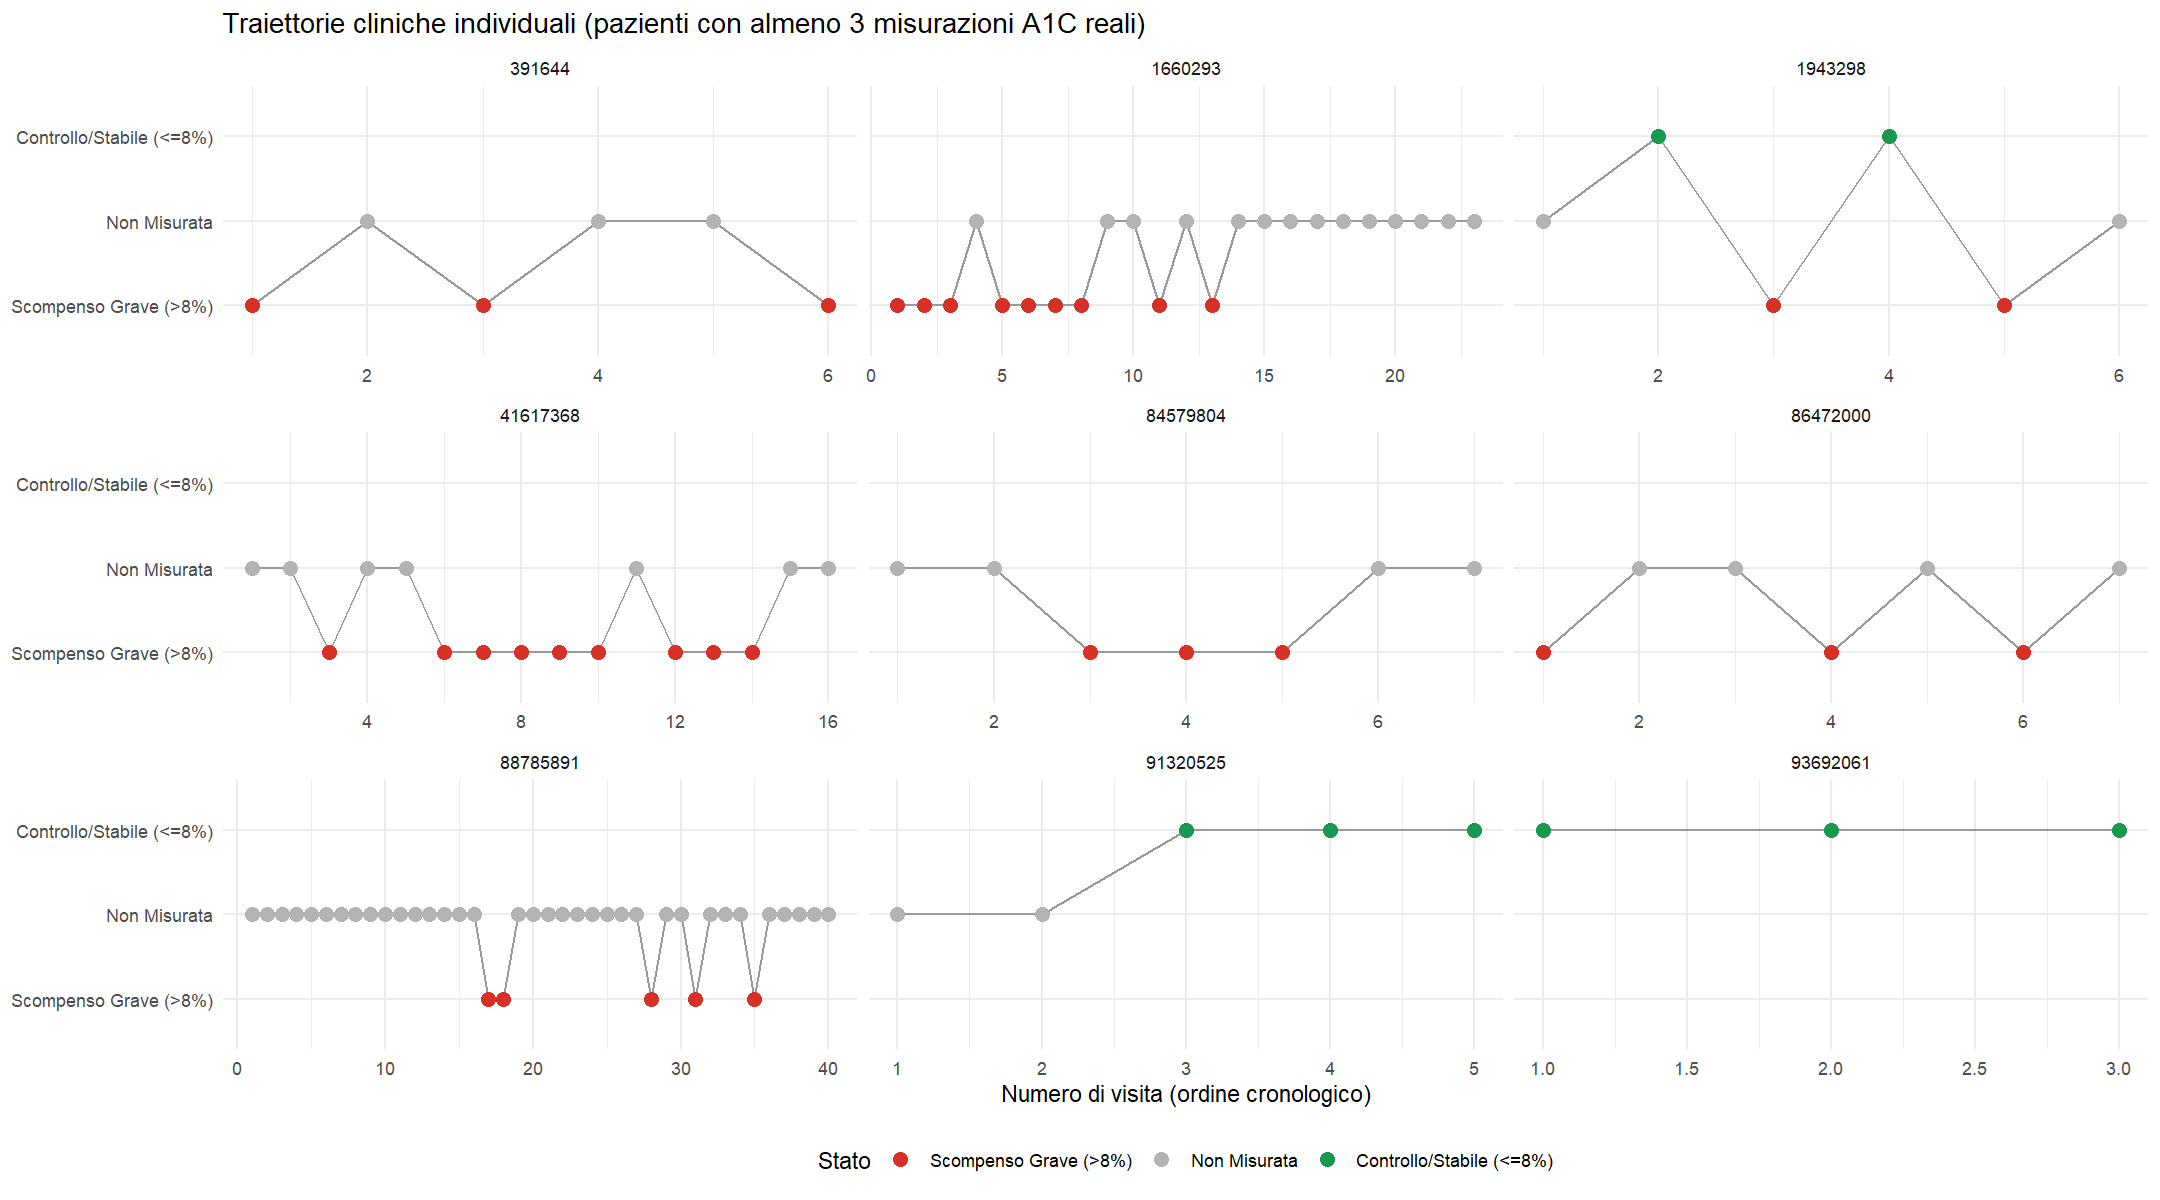

In [14]:
pazienti_con_3_misure <- df_trajectory %>%
  filter(clinical_status != "Non Misurata") %>%
  count(patient_nbr) %>%
  filter(n >= 3) %>%
  pull(patient_nbr)

cat(sprintf("Pazienti con almeno 3 misurazioni A1C reali: %d\n", length(pazienti_con_3_misure)))

set.seed(123)
campione_pazienti <- sample(pazienti_con_3_misure, min(9, length(pazienti_con_3_misure)))

df_traiettorie <- df_trajectory %>%
  filter(patient_nbr %in% campione_pazienti) %>%
  mutate(clinical_status = factor(clinical_status,
                                    levels = c("Scompenso Grave (>8%)", "Non Misurata", "Controllo/Stabile (<=8%)")))

p_traiettorie <- ggplot(df_traiettorie, aes(x = visit_number, y = clinical_status, group = patient_nbr)) +
  geom_line(color = "grey60") +
  geom_point(aes(color = clinical_status), size = 3) +
  facet_wrap(~ patient_nbr, scales = "free_x") +
  scale_color_manual(values = c("Scompenso Grave (>8%)" = "#d73027",
                                  "Non Misurata" = "grey70",
                                  "Controllo/Stabile (<=8%)" = "#1a9850")) +
  labs(title = "Traiettorie cliniche individuali (pazienti con almeno 3 misurazioni A1C reali)",
       x = "Numero di visita (ordine cronologico)", y = NULL, color = "Stato") +
  theme_minimal() +
  theme(legend.position = "bottom")

p_traiettorie

### Interpretazione: traiettorie individuali

Il campione di 9 pazienti mostra pattern diversi. Quattro pazienti (`391644`, `41617368`, `86472000`, `88785891`) oscillano tra Scompenso e Non Misurata senza mai arrivare al controllo, anche su serie lunghe (`88785891` ha 40 visite).

Due pazienti (`93692061`, `91320525` dopo la visita 3) raggiungono il controllo e ci restano per tutte le visite successive osservate, l'esito che McNemar suggeriva senza essere conclusivo.

Un paziente (`1943298`) alterna direttamente tra Controllo e Scompenso senza pause lunghe di Non Misurata: viene testato spesso, ed è vera instabilità clinica, diversa dalla semplice mancanza di misurazioni.

In generale la traiettoria non è quasi mai un singolo passaggio da malato a guarito. È più spesso una sequenza che si ripete uguale, con misurazioni intermittenti. La soglia di guarigione (qui ≤8% invece del <9% originale) va letta come tendenza su più visite, non come evento singolo.

## Task 3.6: il numero di visite segue una distribuzione nota?

Senza visite ripetute non c'è una sequenza da osservare, quindi vale la pena controllare come è distribuito il numero di visite per paziente. Verifichiamo se segue una geometrica (probabilità costante a ogni visita di essere l'ultima) o una binomiale negativa (più realistica, ammette pazienti più o meno inclini a tornare).

Usiamo le visite extra oltre la prima (numero di visite meno 1), per avere supporto da 0 come nelle distribuzioni discrete di R.

In [15]:

visit_counts <- df %>% count(patient_nbr, name = "n_visite")
extra_visite <- visit_counts$n_visite - 1
n <- length(extra_visite)

cat(sprintf("N pazienti: %d\n", n))
cat(sprintf("Media: %.3f | Varianza: %.3f | Rapporto Var/Media: %.3f\n",
            mean(extra_visite), var(extra_visite), var(extra_visite) / mean(extra_visite)))

max_bin <- 6
bins <- pmin(extra_visite, max_bin)
observed <- as.numeric(table(factor(bins, levels = 0:max_bin)))

# Fit Geometrica (stima di massima verosimiglianza)
p_geom <- 1 / (mean(extra_visite) + 1)
prob_geom <- dgeom(0:(max_bin - 1), prob = p_geom)
expected_geom <- n * c(prob_geom, 1 - sum(prob_geom))

chi2_geom <- sum((observed - expected_geom)^2 / expected_geom)
df_geom <- length(observed) - 1 - 1  
p_value_geom <- 1 - pchisq(chi2_geom, df_geom)

# Fit Binomiale Negativa (stima di massima verosimiglianza)
fit_nb <- MASS::fitdistr(extra_visite, "Negative Binomial")
size_nb <- fit_nb$estimate["size"]
mu_nb <- fit_nb$estimate["mu"]
prob_nb <- dnbinom(0:(max_bin - 1), size = size_nb, mu = mu_nb)
expected_nb <- n * c(prob_nb, 1 - sum(prob_nb))

chi2_nb <- sum((observed - expected_nb)^2 / expected_nb)
df_nb <- length(observed) - 1 - 2  
p_value_nb <- 1 - pchisq(chi2_nb, df_nb)

result <- data.frame(
  visite_extra = c(as.character(0:(max_bin - 1)), paste0(max_bin, "+")),
  osservato = observed,
  atteso_geometrica = round(expected_geom, 1),
  atteso_neg_binom = round(expected_nb, 1)
)
print(result)

cat(sprintf("\nGeometrica:          chi2 = %.1f, df = %d, p-value = %.3g\n", chi2_geom, df_geom, p_value_geom))
cat(sprintf("Binomiale Negativa:  chi2 = %.1f, df = %d, p-value = %.3g\n", chi2_nb, df_nb, p_value_nb))

N pazienti: 71509
Media: 0.423 | Varianza: 1.190 | Rapporto Var/Media: 2.813
  visite_extra osservato atteso_geometrica atteso_neg_binom
1            0     54742           50258.4          54894.0
2            1     10431           14935.5           9671.8
3            2      3327            4438.4           3672.8
4            3      1419            1319.0           1644.0
5            4       718             392.0            791.6
6            5       345             116.5            397.3
7           6+       527              49.3            437.5

Geometrica:          chi2 = 7398.1, df = 5, p-value = 0
Binomiale Negativa:  chi2 = 155.4, df = 4, p-value = 0


### Interpretazione: Task 3.6

Il rapporto varianza/media è 2.81, ben oltre 1: alcuni pazienti sono strutturalmente più inclini a tornare di altri, non è un processo omogeneo.

Entrambi i test sono formalmente significativi (p vicino a 0), atteso con 71.509 pazienti. Conta di più la dimensione del Chi quadro: la geometrica ha χ² = 7398, molto alto, la coda dei pazienti con 6 o più visite extra è 10 volte più popolata del previsto (527 osservati contro 49 attesi). La binomiale negativa ha χ² = 155.4, quasi 48 volte più basso, con valori attesi molto più vicini agli osservati.

Il numero di visite non segue una geometrica, ma è coerente con una binomiale negativa: esiste un sottogruppo di pazienti ad alta utilizzazione, probabilmente gli stessi pazienti cronicamente in scompenso visti nelle traiettorie individuali.

## Task 3.7: interpretazione finale e limiti

### Risposta alla RQ

Si può ricostruire la traiettoria clinica di un paziente dall'emoglobina glicata, e non è casuale: lo stato clinico resta uguale da una visita alla successiva più dell'80% delle volte, e il numero di visite segue una distribuzione compatibile con un sottogruppo di pazienti cronici. Il confronto prima/ultima visita suggerisce più miglioramenti che peggioramenti (77 contro 56), ma non in modo statisticamente conclusivo (McNemar, p = 0.083).

### Limiti

1. La soglia di guarigione richiesta era <9%, ma `A1Cresult` è categorico, quindi abbiamo usato la soglia disponibile più vicina (≤8%), un'approssimazione.
2. Solo il 17% degli encounter ha l'A1C misurato, e McNemar si basa su appena 648 pazienti: il p value potrebbe diventare significativo con più dati.
3. L'ordine cronologico è stato validato ma resta un proxy: l'84.3% dei pazienti ha `number_inpatient` non decrescente, non il 100%, quindi piccole inversioni locali sono possibili.
4. L'analisi copre solo i pazienti con A1C misurato. Se i medici lo richiedono più spesso a chi già sospettano in scompenso, il campione non rappresenta tutta la popolazione.
5. Con campioni grandi anche differenze irrilevanti risultano significative, per questo ci siamo basati sugli effect size più che sul p value.
6. Sono stati fatti diversi test senza correggere per confronti multipli.

## Riepilogo

Task 1: variabili numeriche indipendenti tra loro. Tra le categoriche, `change`, `diabetesMed` e `insulin` sono ridondanti (V tra 0.51 e 0.64). Nessuna feature singola predice bene la riammissione. Trovata un'anomalia di data quality su `max_glu_serum`.

Task 2: `weight` eliminata, `payer_code`, `medical_specialty`, `race`, `diag_2`, `diag_3` ricodificate con categoria esplicita, 21 righe eliminate per `diag_1`. Nessun impatto sui risultati del Task 3.

Task 3: traiettoria clinica basata su A1C, ordine cronologico validato empiricamente, stato clinico persistente tra visite (McNemar p = 0.083 sul confronto prima/ultima, persistenza oltre l'80% sulla sequenza completa), numero di visite coerente con una binomiale negativa. Limiti discussi nel Task 3.7.